In [1]:
import pandas as pd
df = pd.read_csv("../data/data.csv", encoding="ISO-8859-1")
print(df.shape)
df.head()


(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12-01-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12-01-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12-01-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12-01-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12-01-2010 08:26,3.39,17850.0,United Kingdom


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Load data using relative path
df = pd.read_csv("../data/data.csv", encoding="ISO-8859-1")
print("Original shape:", df.shape)


Original shape: (541909, 8)


In [2]:
df.info()
print("\nMissing values per column:")
print(df.isnull().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB

Missing values per column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [5]:
rows_start = len(df)

# 1. Remove rows with no customer ID 
df = df.dropna(subset=["CustomerID"])
print("After removing missing CustomerID:", len(df))

# 2. Remove duplicate rows
df = df.drop_duplicates()
print("After removing duplicates:", len(df))

# 3. Remove cancelled orders (invoice numbers starting with 'C')
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]
print("After removing cancellations:", len(df))

# 4. Remove negative or zero quantity and price
df = df[(df["Quantity"] > 0) & (df['UnitPrice'] > 0)]
print("After removing bad quantity/price:", len(df))

# 5. Fix data types and add a Revenue column
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], format='mixed')
df["CustomerID"] = df["CustomerID"].astype(int)
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

print(f"\nStarted with {rows_start} rows, ended with {len(df)} rows")
df.head()


After removing missing CustomerID: 392692
After removing duplicates: 392692
After removing cancellations: 392692
After removing bad quantity/price: 392692

Started with 392692 rows, ended with 392692 rows


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [6]:
print("Total revenue:", round(df["Revenue"].sum(), 2))
print("Unique customers:", df["CustomerID"].nunique())
print("Unique orders:", df["InvoiceNo"].nunique())
print("Unique products:", df["StockCode"].nunique())
print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())
print("Average order value:", round(df.groupby("InvoiceNo")["Revenue"].sum().mean(), 2))


Total revenue: 8887208.89
Unique customers: 4338
Unique orders: 18532
Unique products: 3665
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
Average order value: 479.56


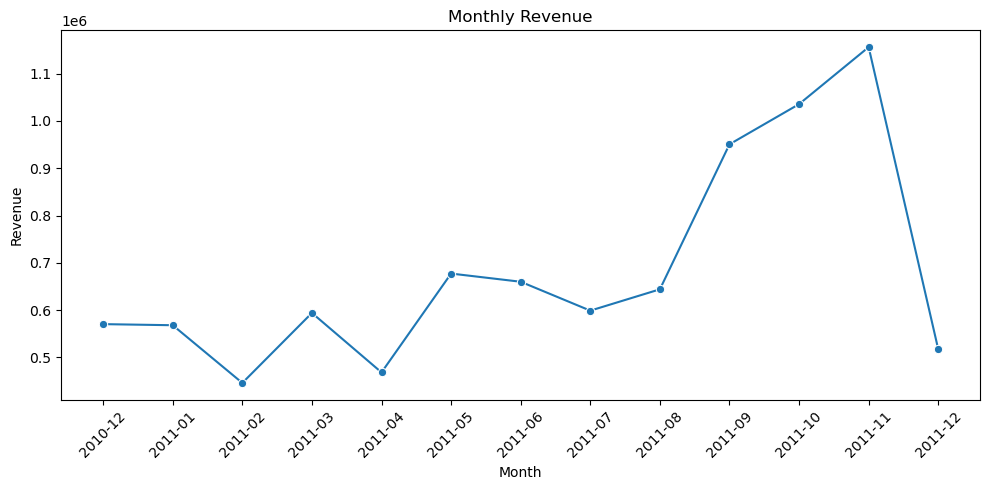

In [7]:
df["Month"] = df["InvoiceDate"].dt.to_period("M").astype(str)
monthly = df.groupby("Month")["Revenue"].sum().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(data=monthly, x="Month", y="Revenue", marker="o")
plt.xticks(rotation=45)
plt.title("Monthly Revenue")
plt.tight_layout()
plt.savefig("../images/monthly_revenue.png", dpi=150)
plt.show()


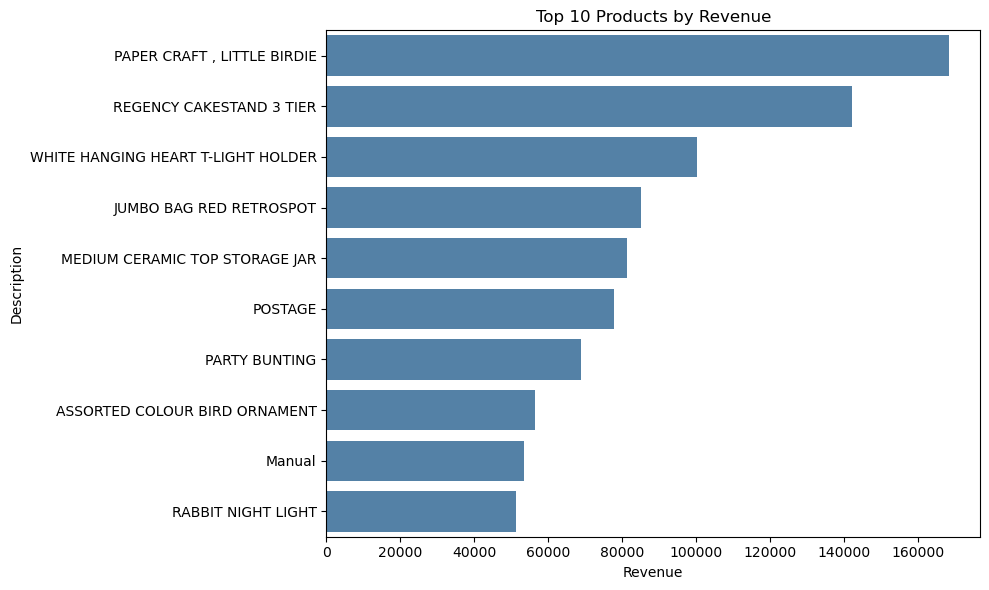

In [8]:
top = df.groupby("Description")["Revenue"].sum().nlargest(10).reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(data=top, x="Revenue", y="Description", color="steelblue")
plt.title("Top 10 Products by Revenue")
plt.tight_layout()
plt.savefig("../images/top_products.png", dpi=150)
plt.show()


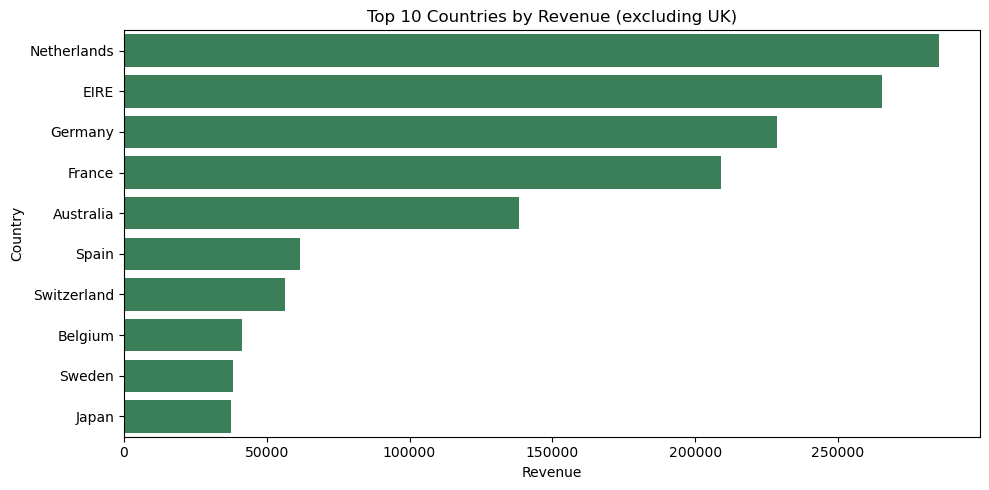

UK share of revenue: 82.0%


In [9]:
countries = (df[df["Country"] != "United Kingdom"]
             .groupby("Country")["Revenue"].sum().nlargest(10).reset_index())

plt.figure(figsize=(10, 5))
sns.barplot(data=countries, x="Revenue", y="Country", color="seagreen")
plt.title("Top 10 Countries by Revenue (excluding UK)")
plt.tight_layout()
plt.savefig("../images/top_countries.png", dpi=150)
plt.show()

uk_share = df[df["Country"] == "United Kingdom"]["Revenue"].sum() / df["Revenue"].sum()
print(f"UK share of revenue: {uk_share:.1%}")


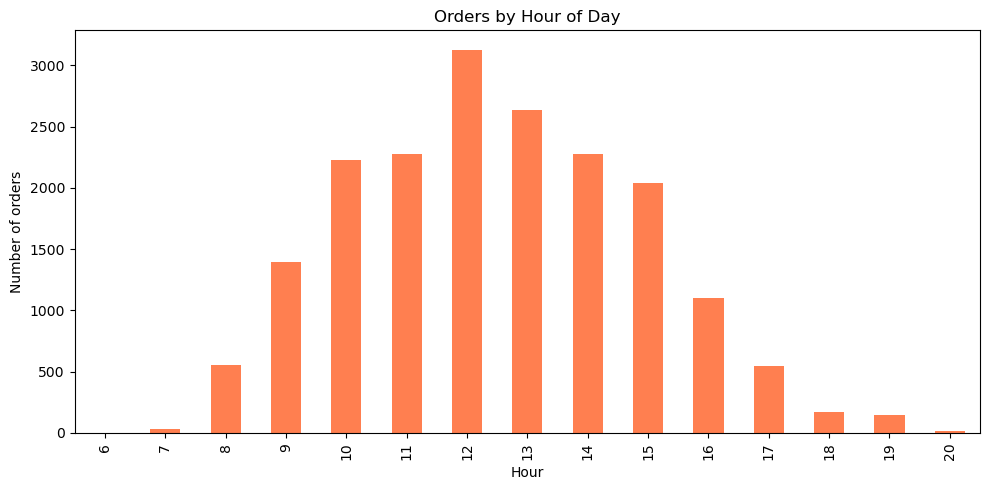

In [10]:
df["Hour"] = df["InvoiceDate"].dt.hour
df["DayOfWeek"] = df["InvoiceDate"].dt.day_name()

hourly = df.groupby("Hour")["InvoiceNo"].nunique()
plt.figure(figsize=(10, 5))
hourly.plot(kind="bar", color="coral")
plt.title("Orders by Hour of Day")
plt.ylabel("Number of orders")
plt.tight_layout()
plt.savefig("../images/orders_by_hour.png", dpi=150)
plt.show()


In [11]:
fig = px.line(monthly, x="Month", y="Revenue", title="Monthly Revenue (interactive)", markers=True)
fig.show()


In [12]:
df.to_csv("../data/cleaned_data.csv", index=False)
print("Cleaned file saved successfully.")


Cleaned file saved successfully.


In [ ]:
df.to_csv("../data/cleaned_data.csv", index=False)
print("Cleaned data file saved successfully in data/ folder.")
